In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
Data = pd.read_csv('xrd_vegard_linear_regression.csv')
Data.head(2)

,sample_id,Ge_content_at_pct,peak_111_two_theta_deg,lattice_parameter_A
0,X000,31.24,28.094,5.4997
1,X001,24.23,28.192,5.4770


In [14]:
Data['lattice_parameter_A'].shape

(200,)

Text(0, 0.5, 'Intensity')

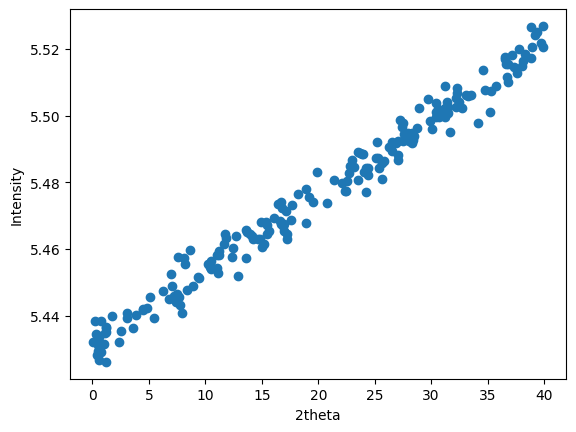

In [17]:
plt.scatter(Data['Ge_content_at_pct'],	Data['lattice_parameter_A'])
plt.xlabel('2theta')
plt.ylabel('Intensity')

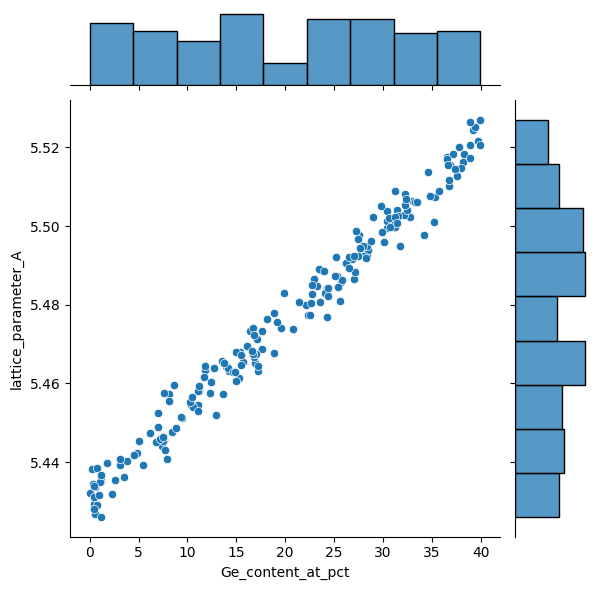

In [5]:
sns.jointplot(Data, x='Ge_content_at_pct',	y='lattice_parameter_A')


In [61]:
X = Data[['Ge_content_at_pct']]
Y = Data[['lattice_parameter_A']]

In [62]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 2)


In [63]:
X_test

,Ge_content_at_pct
112,23.85
29,7.64
182,1.17
199,31.47
193,37.32
85,25.61
10,7.89
54,23.66
115,0.26
35,15.36


In [64]:
Y_test

,lattice_parameter_A
112,5.4886
29,5.4457
182,5.4367
199,5.5008
193,5.5146
85,5.4809
10,5.4407
54,5.4887
115,5.4383
35,5.4681


In [65]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Ge_content_at_pct']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[5.43]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [66]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

Y_pred = lr.predict(X_test)

print('r2 score is', r2_score(Y_pred, Y_test))
print('MAE is', mean_absolute_error(Y_pred, Y_test))
print('MSE is', mean_squared_error(Y_pred, Y_test))

r2 score is 0.9713923967669429
MAE is 0.0036529292688993074
MSE is 1.9499530118260633e-05


In [67]:
lr.predict(X_test.iloc[0].values.reshape(1, 1))

C:\Users\lands\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([[5.48511246]])

Text(0, 0.5, 'Intensity')

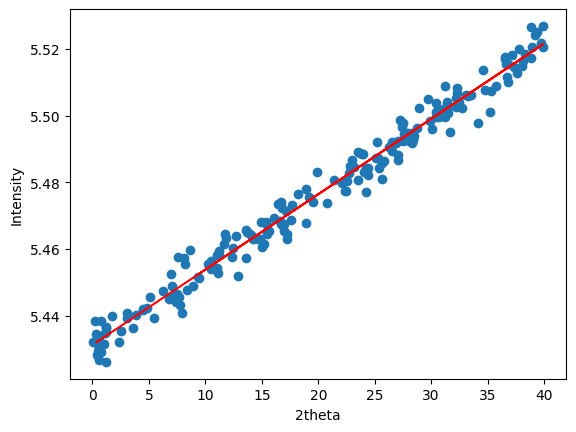

In [68]:
plt.scatter(Data['Ge_content_at_pct'],	Data['lattice_parameter_A'])
plt.plot(X_train, lr.predict(X_train), color = 'red')
plt.xlabel('2theta')
plt.ylabel('Intensity')

Text(0, 0.5, 'Intensity')

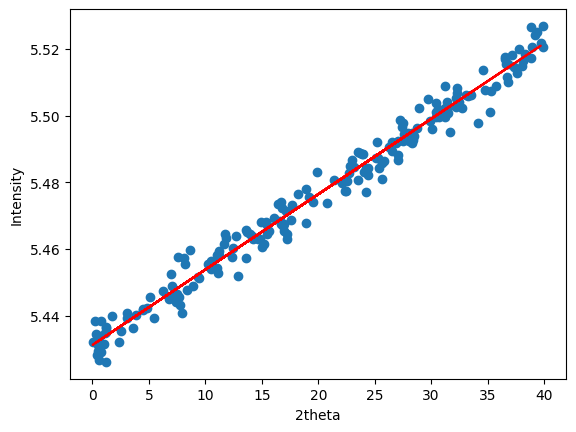

In [48]:
plt.scatter(Data['Ge_content_at_pct'],	Data['lattice_parameter_A'])
plt.plot(X_test, lr.predict(X_test), color = 'red')
plt.xlabel('2theta')
plt.ylabel('Intensity')

### slope and intercept value 

In [49]:
m = lr.coef_

In [50]:
b = lr.intercept_

In [52]:
## y = mx + b

m * 25.61 + b   ## we got the same value as predicted

array([[5.48909155]])

In [54]:
m * 3.56 + b

array([[5.43923989]])

In [3]:
Data2 = pd.read_csv('xrd_vegard_linear_regression.csv')
Data2.head(2)

,sample_id,Ge_content_at_pct,peak_111_two_theta_deg,lattice_parameter_A
0,X000,31.24,28.094,5.4997
1,X001,24.23,28.192,5.4770


In [4]:
X2 = Data2[['Ge_content_at_pct']]
Y2 = Data2[['lattice_parameter_A']]

In [7]:
from sklearn.model_selection import train_test_split

X2_train, X2_test, Y2_train, Y2_test = train_test_split(X2, Y2, test_size = 0.2, random_state = 2) 
X2_train.head()

,Ge_content_at_pct
137,9.47
163,11.69
111,13.94
123,17.00
109,18.90


In [8]:
from sklearn.linear_model import LinearRegression

Lr = LinearRegression()

Lr.fit(X2_train, Y2_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Ge_content_at_pct']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[5.43]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [11]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

Y_pred2 = Lr.predict(X2_test)

print('r2 score is', r2_score(Y_pred2, Y2_test))
print('MAE is', mean_absolute_error(Y_pred2, Y2_test))
print('MSE is', mean_squared_error(Y_pred2, Y2_test))

r2 score is 0.9713923967669429
MAE is 0.0036529292688993074
MSE is 1.9499530118260633e-05


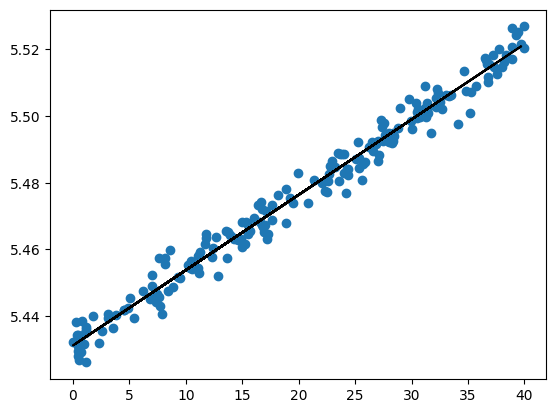

In [21]:
plt.scatter(Data2['Ge_content_at_pct'], Data2['lattice_parameter_A'])
plt.plot(X2_test, Lr.predict(X2_test), color = 'black')
plt.show()

In [22]:
X2_test.shape

(40, 1)

In [24]:
r2 = r2_score(Y2_test, Y_pred2)
print(1- ((1-r2)*(40-1)/(40-1-1)))

0.9703391109900894


In [26]:
Data2.head(2)

,sample_id,Ge_content_at_pct,peak_111_two_theta_deg,lattice_parameter_A
0,X000,31.24,28.094,5.4997
1,X001,24.23,28.192,5.4770


In [28]:
X3 = Data2[['Ge_content_at_pct', 'peak_111_two_theta_deg']]
Y3 = Data2[['lattice_parameter_A']]

In [29]:
X3_train, X3_test, Y3_train, Y3_test = train_test_split(X3, Y3, test_size = 0.2, random_state = 2) 


In [30]:
Lo = LinearRegression()

Lo.fit(X3_train, Y3_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 2)","[[ 0. ,-0.15]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Ge_content_at_pct','peak_111_two_theta_deg']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[9.64]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [31]:
Y_pred3 = Lo.predict(X3_test)

print('r2 score is', r2_score(Y_pred3, Y3_test))
print('MAE is', mean_absolute_error(Y_pred3, Y3_test))
print('MSE is', mean_squared_error(Y_pred3, Y3_test))

r2 score is 0.9970466716007362
MAE is 0.0011033800763734947
MSE is 1.9503053023242283e-06


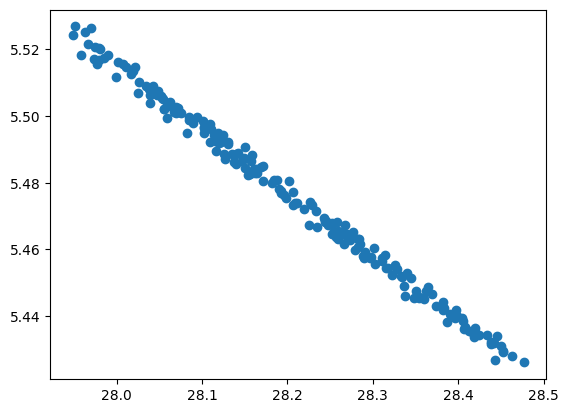

In [35]:
plt.scatter(Data2['peak_111_two_theta_deg'], Data2['lattice_parameter_A'])

plt.show()

In [8]:
Df = pd.read_csv('qmof.csv', low_memory=False)
Df.tail(20)

,qmof_id,name,info.formula,info.formula_reduced,info.mofid.mofid,info.mofid.mofkey,info.mofid.smiles_nodes,info.mofid.smiles_linkers,info.mofid.smiles,info.mofid.topology,...,outputs.hse06.energy_elec,outputs.hse06.net_magmom,outputs.hse06.bandgap,outputs.hse06.cbm,outputs.hse06.vbm,outputs.hse06.directgap,outputs.hse06.bandgap_spins,outputs.hse06.cbm_spins,outputs.hse06.vbm_spins,outputs.hse06.directgap_spins
20352,qmof-b44aef2,tobacco_srsb_sym_3_on_0_sym_3_mc_0_L_14,Cu12C84H72N28,Cu3C21H18N7,C(=CN(C=CC=CC1=C[N]N=C1)C=CC=CC1=C[N]N=C1)C=CC...,Cu.OJFMPXUFDTYVGL.MOFkey-v1.srs,['[Cu]'],['C(=CN(C=CC=CC1=C[N]N=C1)C=CC=CC1=C[N]N=C1)C=...,C(=CN(C=CC=CC1=C[N]N=C1)C=CC=CC1=C[N]N=C1)C=CC...,srs,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20353,qmof-d475ee7,tobacco_srsb_sym_3_on_0_sym_3_mc_0_L_19,Cu12C132H72N28,Cu3C33H18N7,N1=C[C](C=N1)C#Cc1ccc(cc1)N(c1ccc(cc1)C#CC1=C[...,Cu.GISXUFCKSNXRDB.MOFkey-v1.srs,['[Cu]'],['N1=C[C](C=N1)C#Cc1ccc(cc1)N(c1ccc(cc1)C#CC1=...,N1=C[C](C=N1)C#Cc1ccc(cc1)N(c1ccc(cc1)C#CC1=C[...,srs,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20354,qmof-6a62f82,tobacco_srsb_sym_3_on_0_sym_3_mc_0_L_2,Cu12C60H48N28,Cu3C15H12N7,C(=CN(C=C[C]1C=NN=C1)C=C[C]1C=NN=C1)[C]1C=NN=C...,Cu.HAYJUPGUWCQQBL.MOFkey-v1.srs,['[Cu]'],['C(=CN(C=C[C]1C=NN=C1)C=C[C]1C=NN=C1)[C]1C=NN...,C(=CN(C=C[C]1C=NN=C1)C=C[C]1C=NN=C1)[C]1C=NN=C...,srs,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20355,qmof-1b24ed6,tobacco_srsb_sym_3_on_0_sym_3_mc_0_L_5,Cu12C84H48N28O12,Cu3C21H12N7O3,N1=C[C](C=N1)c1ccc(o1)N(c1ccc(o1)C1=C[N]N=C1)c...,Cu.ZEVCOCUHFRPENL.MOFkey-v1.srs,"['[Cu]', '[Cu][Cu]']",['N1=C[C](C=N1)c1ccc(o1)N(c1ccc(o1)C1=C[N]N=C1...,N1=C[C](C=N1)c1ccc(o1)N(c1ccc(o1)C1=C[N]N=C1)c...,srs,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20356,qmof-50252e9,tobacco_srsb_sym_3_on_0_sym_3_mc_0_L_6,Cu12C60H36N64,Cu3C15H9N16,N1=C[C](C=N1)n1nnc(c1)N(c1nnn(c1)C1=C[N]N=C1)c...,Cu.UYDWFYRKEKPWST.MOFkey-v1.srs,['[Cu]'],['N1=C[C](C=N1)n1nnc(c1)N(c1nnn(c1)C1=C[N]N=C1...,N1=C[C](C=N1)n1nnc(c1)N(c1nnn(c1)C1=C[N]N=C1)c...,srs,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20357,qmof-3873aad,tobacco_srsb_sym_3_on_0_sym_3_mc_0__,Cu12C36H24N28,Cu3C9H6N7,N1=C[C](C=N1)N(C1=C[N]N=C1)C1=C[N]N=C1.N1=C[C]...,Cu.AHBOORMGBLZGCH.MOFkey-v1.srs,['[Cu]'],"['N1=C[C](C=N1)N(C1=C[N]N=C1)C1=C[N]N=C1', 'N1...",N1=C[C](C=N1)N(C1=C[N]N=C1)C1=C[N]N=C1.N1=C[C]...,srs,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20358,qmof-eb5e701,tobacco_srsb_sym_3_on_1_sym_3_mc_0_L_12,Cu12C120H72N36,CuC10H6N3,N1=C[C](C=N1)c1ccc(cc1)C1=NC(=[N]=C([N]1)c1ccc...,Cu.ZNGQJRFFYQKCBV.MOFkey-v1.srs,['[Cu]'],['N1=C[C](C=N1)c1ccc(cc1)C1=NC(=[N]=C([N]1)c1c...,N1=C[C](C=N1)c1ccc(cc1)C1=NC(=[N]=C([N]1)c1ccc...,srs,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20359,qmof-b3742a4,tobacco_srsb_sym_3_on_1_sym_3_mc_0_L_13,Cu12C72H24N84,CuC6H2N7,N1=C[C](C=N1)C1=N[N]C(=N[N]1)C1=NC(=[N]=C([N]1...,Cu.YAQGBQUHCISRLY.MOFkey-v1.srs,['[Cu]'],['N1=C[C](C=N1)C1=N[N]C(=N[N]1)C1=NC(=[N]=C([N...,N1=C[C](C=N1)C1=N[N]C(=N[N]1)C1=NC(=[N]=C([N]1...,srs,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20360,qmof-efd24b7,tobacco_srsb_sym_3_on_1_sym_3_mc_0_L_14,Cu12C96H72N36,CuC8H6N3,C(=C[C]1C=NN=C1)C=CC1=[N]=C(N=C([N]1)C=CC=CC1=...,Cu.VIXCORHAMSYOSG.MOFkey-v1.srs,['[Cu]'],['C(=C[C]1C=NN=C1)C=CC1=[N]=C(N=C([N]1)C=CC=CC...,C(=C[C]1C=NN=C1)C=CC1=[N]=C(N=C([N]1)C=CC=CC1=...,srs,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20361,qmof-cb91326,tobacco_srsb_sym_3_on_1_sym_3_mc_0_L_2,Cu12C72H48N36,CuC6H4N3,N1=C[C](C=N1)C=CC1=NC(=[N]=C([N]1)C=CC1=C[N]N=...,Cu.RBVJOVWEIJBLOV.MOFkey-v1.srs,['[Cu]'],['N1=C[C](C=N1)C=CC1=NC(=[N]=C([N]1)C=CC1=C[N]...,N1=C[C](C=N1)C=CC1=NC(=[N]=C([N]1)C=CC1=C[N]N=...,srs,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
Df.columns

Index(['qmof_id', 'name', 'info.formula', 'info.formula_reduced',
       'info.mofid.mofid', 'info.mofid.mofkey', 'info.mofid.smiles_nodes',
       'info.mofid.smiles_linkers', 'info.mofid.smiles', 'info.mofid.topology',
       'info.natoms', 'info.pld', 'info.lcd', 'info.density', 'info.volume',
       'info.symmetry.spacegroup', 'info.symmetry.spacegroup_number',
       'info.symmetry.spacegroup_crystal', 'info.symmetry.pointgroup',
       'info.synthesized', 'info.source', 'info.doi', 'inputs.pbe.theory',
       'inputs.pbe.pseudopotentials', 'inputs.pbe.encut', 'inputs.pbe.kpoints',
       'inputs.pbe.gamma', 'inputs.pbe.spin', 'outputs.pbe.energy_total',
       'outputs.pbe.energy_vdw', 'outputs.pbe.energy_elec',
       'outputs.pbe.net_magmom', 'outputs.pbe.bandgap', 'outputs.pbe.cbm',
       'outputs.pbe.vbm', 'outputs.pbe.directgap', 'outputs.pbe.bandgap_spins',
       'outputs.pbe.cbm_spins', 'outputs.pbe.vbm_spins',
       'outputs.pbe.directgap_spins', 'inputs.hle17.theory',

In [10]:
Df.isnull().sum()

qmof_id                              0
name                                 0
info.formula                         0
info.formula_reduced                 0
info.mofid.mofid                 12910
                                 ...  
outputs.hse06.directgap           9562
outputs.hse06.bandgap_spins       9562
outputs.hse06.cbm_spins           9562
outputs.hse06.vbm_spins           9562
outputs.hse06.directgap_spins     9562
Length: 94, dtype: int64

In [11]:
cols = ['info.density', 'info.pld', 'info.lcd', 'info.volume', 'info.natoms', 'outputs.pbe.bandgap']
Df2 = Df[cols].dropna()
Df2

,info.density,info.pld,info.lcd,info.volume,info.natoms,outputs.pbe.bandgap
0,2.763246,0.68822,1.35480,408.857471,39,0.632527
1,3.229952,1.18570,2.13507,1781.965032,128,1.134232
2,1.557644,2.36128,4.21176,1292.643180,108,0.345448
3,1.616139,2.14542,3.27957,1245.856916,108,0.342645
4,1.596537,1.33452,2.03948,1148.155557,102,1.973007
...,...,...,...,...,...,...
20367,0.170101,19.56940,21.72285,21165.032290,180,2.692705
20368,0.162440,20.80552,23.38392,27194.106450,204,3.326284
20369,0.380963,10.86124,13.89036,8088.346461,132,3.383629
20370,0.132949,23.17582,24.75512,31431.035640,220,0.660589


In [47]:
Df2.isnull().sum()

info.density           0
info.pld               0
info.lcd               0
info.volume            0
info.natoms            0
outputs.pbe.bandgap    0
dtype: int64

In [50]:
X_1 = Df2.iloc[:, 0:5]
Y_1 = Df2.iloc[:, 5]

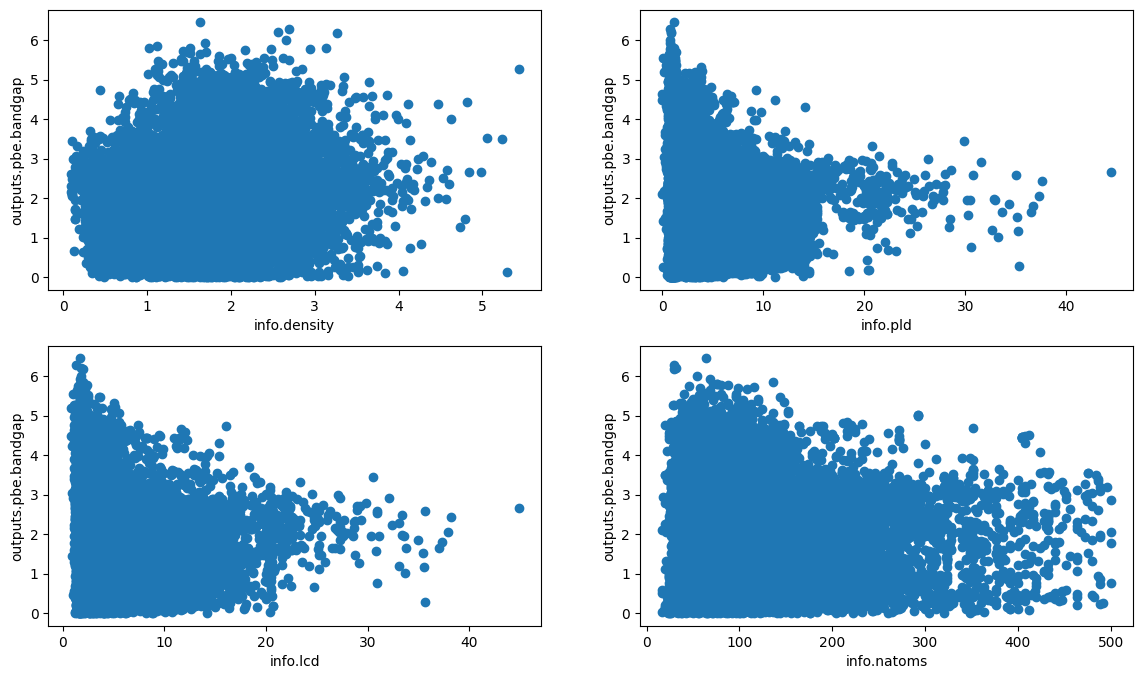

In [12]:
plt.figure(figsize=(14,8))

plt.subplot(221)
plt.scatter(Df2['info.density'],	Df2['outputs.pbe.bandgap'])
plt.xlabel('info.density')
plt.ylabel('outputs.pbe.bandgap')


plt.subplot(222)
plt.scatter(Df2['info.pld'],	Df2['outputs.pbe.bandgap'])
plt.xlabel('info.pld')
plt.ylabel('outputs.pbe.bandgap')


plt.subplot(223)
plt.scatter(Df2['info.lcd'],	Df2['outputs.pbe.bandgap'])
plt.xlabel('info.lcd')
plt.ylabel('outputs.pbe.bandgap')

plt.subplot(224)
plt.scatter(Df2['info.natoms'],	Df2['outputs.pbe.bandgap'])
plt.xlabel('info.natoms')
plt.ylabel('outputs.pbe.bandgap')


plt.show()

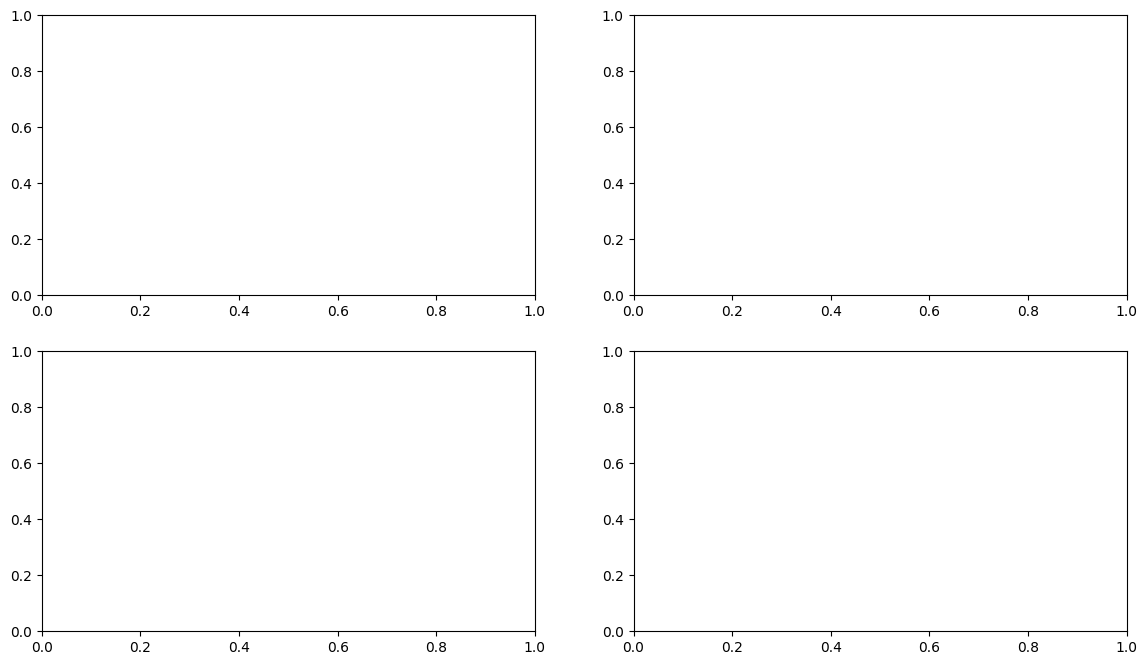

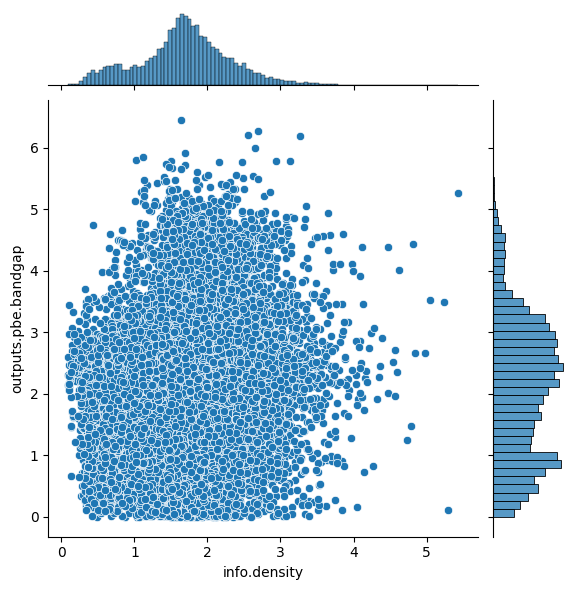

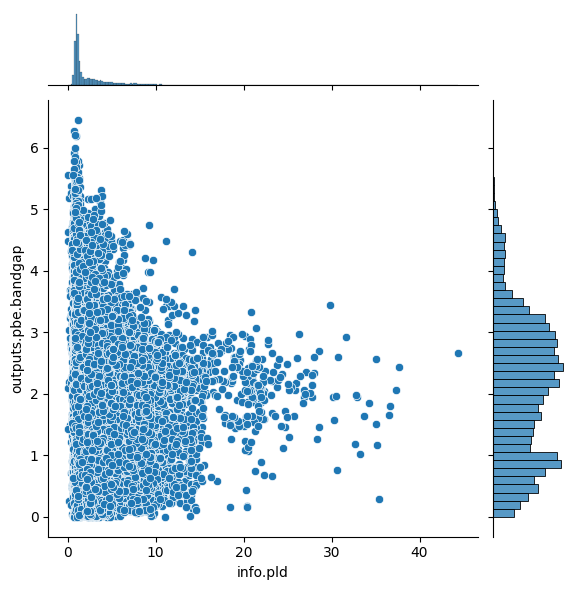

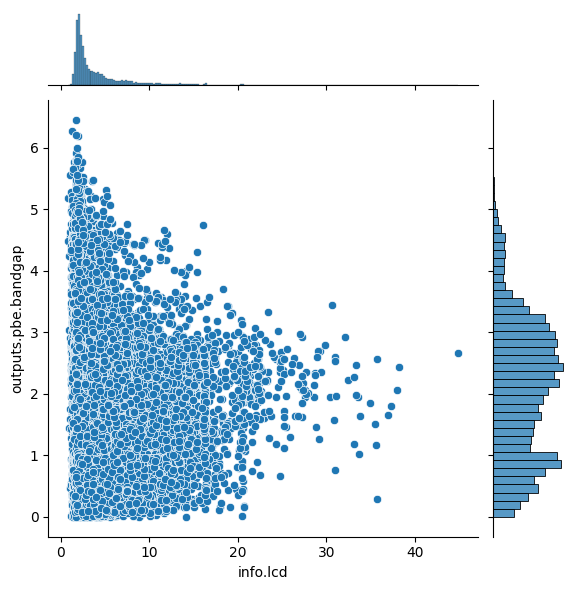

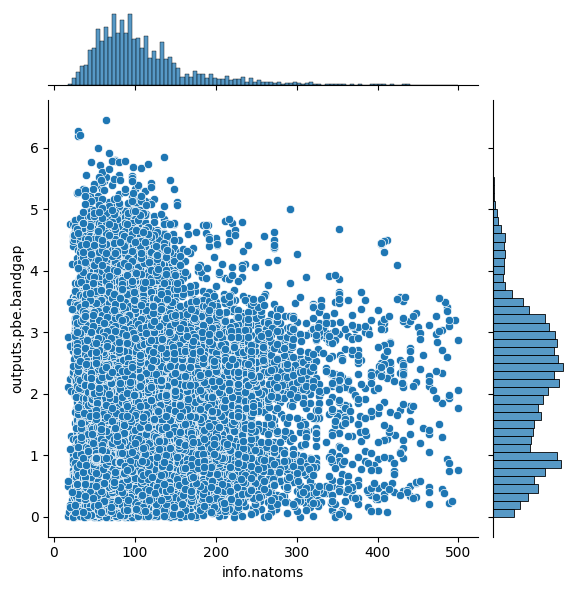

In [15]:

fig, axes = plt.subplots(2, 2, figsize=(14,8))

sns.jointplot(Df2, x='info.density', y='outputs.pbe.bandgap')

sns.jointplot(Df2, x='info.pld',	y='outputs.pbe.bandgap')

sns.jointplot(Df2, x='info.lcd',	y='outputs.pbe.bandgap')

sns.jointplot(Df2, x='info.natoms',	y='outputs.pbe.bandgap')


In [ ]:
plt.figure(figsize=(14,8))

plt.subplot(221)
sns.jointplot(Df2, x='info.density', y='outputs.pbe.bandgap')
plt.xlabel('info.density')
plt.ylabel('outputs.pbe.bandgap')


plt.subplot(222)
plt.scatter(Df2['info.pld'],	Df2['outputs.pbe.bandgap'])
plt.xlabel('info.pld')
plt.ylabel('outputs.pbe.bandgap')


plt.subplot(223)
plt.scatter(Df2['info.lcd'],	Df2['outputs.pbe.bandgap'])
plt.xlabel('info.lcd')
plt.ylabel('outputs.pbe.bandgap')

plt.subplot(224)
plt.scatter(Df2['info.natoms'],	Df2['outputs.pbe.bandgap'])
plt.xlabel('info.natoms')
plt.ylabel('outputs.pbe.bandgap')


plt.show()

In [60]:
X4_train, X4_test, Y4_train, Y4_test = train_test_split(X_1, Y_1, test_size = 0.3, random_state = 2)
X4_train.shape

(14260, 5)

In [58]:
L4 = LinearRegression()

L4.fit(X4_train, Y4_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 0.34,-0.02, 0. , 0. ,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['info.density','info.pld','info.lcd','info.volume','info.natoms']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.516
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [59]:
Y4_pred = L4.predict(X4_test)

print('r2 score is', r2_score(Y4_test, Y4_pred))
print('MAE is', mean_absolute_error(Y4_test, Y4_pred))
print('MSE is', mean_squared_error(Y4_test, Y4_pred))

r2 score is 0.04449520847000055
MAE is 0.9195400926378009
MSE is 1.2343583863789187


In [62]:
r2_4 = r2_score(Y4_test, Y4_pred)
print(1-((1-r2_4) * (14260 - 1)/(14260-1-5)))

0.044160037713886546


In [17]:
AI = pd.read_csv('ai_agents_synthetic.csv')
AI.head(2)

,agent_id,agent_type,model_size_b,context_window_k,num_tools,reasoning_steps,training_examples_k,memory_enabled,avg_cost_usd,avg_latency_s,benchmark_score
0,agent_0001,customer_support,168.7,64,8,15,372.9,1,0.397,28.1,73.9
1,agent_0002,web_browsing,89.8,128,5,14,451.3,1,0.873,22.4,60.5


In [20]:
AI.isnull().sum()

agent_id               0
agent_type             0
model_size_b           0
context_window_k       0
num_tools              0
reasoning_steps        0
training_examples_k    0
memory_enabled         0
avg_cost_usd           0
avg_latency_s          0
benchmark_score        0
dtype: int64

In [27]:
X_ = AI[['avg_latency_s', 'model_size_b']]
Y_ = AI['benchmark_score']

In [28]:
from sklearn.model_selection import train_test_split

X_train1, X_test1, Y_train1, Y_test1 = train_test_split(X_, Y_, test_size = 0.2, random_state = 2) 
X_train1

,avg_latency_s,model_size_b
333,19.8,28.6
721,31.8,161.7
1352,16.1,8.7
1680,35.9,147.8
156,43.9,20.5
...,...,...
1558,23.6,124.9
1608,9.5,40.6
493,44.9,184.7
527,33.4,180.6


In [30]:
from sklearn.preprocessing import StandardScaler

S1 = StandardScaler()
X_train1_trf = S1.fit_transform(X_train1)
X_test1_trf = S1.transform(X_test1)

In [32]:
from sklearn.linear_model import LinearRegression

L1 = LinearRegression()

L1.fit(X_train1_trf, Y_train1)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[2.23,6.71]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,59.22
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[44.79,34.55]"


In [34]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

y_pred = L1.predict(X_test1_trf)

print('r2 score is', r2_score(Y_test1, y_pred))
print('MAE is', mean_absolute_error(Y_test1, y_pred))
print('MSE is', mean_squared_error(Y_test1, y_pred))

r2 score is 0.26716071028855815
MAE is 7.448581810413006
MSE is 88.92739011899688


In [38]:
r2_s = r2_score(Y_test1, y_pred)
print(1-((1-r2_s) * (400 - 1)/(400-1-5)))

0.2578607193023723


In [37]:
L1.coef_

array([2.23316751, 6.70977224])

In [40]:
dict(zip(X_train1.columns, L1.coef_))

{'avg_latency_s': np.float64(2.2331675124752115),
 'model_size_b': np.float64(6.709772239475996)}